In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [ ]:
df = pd.read_csv('/content/nigerian_diabetes_dataset.csv')
df.head()

,Patient_ID,Age,Gender,State_of_Residence,Diabetes_Type,HbA1c_Percent,Fasting_Blood_Glucose_mgdL,Primary_Complication,Treatment_Regimen
0,NGA-DB-001,69,Female,FCT,Type 2,11.8,195.0,NaN,Metformin Monotherapy
1,NGA-DB-002,32,Male,Borno,Type 2,5.7,105.0,Hypertension,Metformin Monotherapy
2,NGA-DB-003,78,Male,Borno,Type 2,11.6,228.0,Neuropathy,Metformin + Insulin
3,NGA-DB-004,38,Male,Oyo,Type 2,7.6,138.0,NaN,Diet & Exercise Only
4,NGA-DB-005,41,Female,Oyo,Type 2,6.4,120.0,Neuropathy,Insulin Therapy


In [ ]:
x = df.drop('Diabetes_Type', axis=1)
y = df['Diabetes_Type']

In [ ]:
# Drop Patient_ID since it is a unique identifier and causes data leakage/memorization
x = x.drop(columns=['Patient_ID'], errors='ignore')

# Identify numerical and categorical features
numeric_features = x.select_dtypes(include=[np.number]).columns
categorical_features = x.select_dtypes(include=['object']).columns

In [ ]:
# 1. Re-split train/test using the updated x (which excludes Patient_ID)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# 2. Define transformers
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 3. Combine with ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# 4. Create and train pipeline with RandomForestClassifier
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_split=20, min_samples_leaf=10, class_weight='balanced', criterion='gini', random_state=42))
])

clf.fit(x_train, y_train)
y_pred = clf.predict(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 1.0
              precision    recall  f1-score   support

      Type 2       1.00      1.00      1.00        20

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [ ]:
# 4. Re-create and re-train the DecisionTreeClassifier pipeline using the clean features (excluding Patient_ID)
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

unique_labels = ['Type 1', 'Type 2']
print(classification_report(y_test, y_pred, labels=unique_labels))
print(confusion_matrix(y_test, y_pred, labels=unique_labels))

Accuracy: 1.0
              precision    recall  f1-score   support

      Type 1       0.00      0.00      0.00         0
      Type 2       1.00      1.00      1.00        20

    accuracy                           1.00        20
   macro avg       0.50      0.50      0.50        20
weighted avg       1.00      1.00      1.00        20

[[ 0  0]
 [ 0 20]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/me

In [ ]:
# Print the train and test evaluation scores of our trained model pipeline
print("Train Score:", model.score(x_train, y_train))
print("Test Score:", model.score(x_test, y_test))

print("\nClassification Report:")
unique_labels = ['Type 1', 'Type 2']
print(classification_report(y_test, y_pred, labels=unique_labels))

Train Score: 1.0
Test Score: 1.0

Classification Report:
              precision    recall  f1-score   support

      Type 1       0.00      0.00      0.00         0
      Type 2       1.00      1.00      1.00        20

    accuracy                           1.00        20
   macro avg       0.50      0.50      0.50        20
weighted avg       1.00      1.00      1.00        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/me

In [ ]:
# Retrieve feature names and importances
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
feature_importances = model.named_steps['classifier'].feature_importances_

# Create a Series sorted by importance
importances = pd.Series(feature_importances, index=feature_names).sort_values(ascending=False)

print("\nTop 10 important features:")
print(importances.head(10))


Top 10 important features:
cat__Patient_ID_NGA-DB-076    0.208304
cat__Patient_ID_NGA-DB-068    0.202894
cat__Patient_ID_NGA-DB-044    0.198424
cat__Patient_ID_NGA-DB-092    0.197691
cat__Patient_ID_NGA-DB-043    0.192687
cat__Patient_ID_NGA-DB-003    0.000000
num__Age                      0.000000
num__HbA1c_Percent            0.000000
cat__Patient_ID_NGA-DB-007    0.000000
cat__Patient_ID_NGA-DB-006    0.000000
dtype: float64


In [ ]:
# Create a valid mock instance using the correct feature columns
new_data = pd.DataFrame([{
    'Age': 45,
    'Gender': 'Female',
    'State_of_Residence': 'FCT',
    'HbA1c_Percent': 8.5,
    'Fasting_Blood_Glucose_mgdL': 160.0,
    'Primary_Complication': 'Hypertension',
    'Treatment_Regimen': 'Metformin Monotherapy'
}], columns=x.columns)

# Predict using the RandomForest pipeline
print("Random Forest Prediction:", clf.predict(new_data))
print("Random Forest Probabilities:", clf.predict_proba(new_data))

# Predict using the DecisionTree pipeline
print("Decision Tree Prediction:", model.predict(new_data))

Random Forest Prediction: ['Type 2']
Random Forest Probabilities: [[0.25508822 0.16338183 0.58152995]]
Decision Tree Prediction: ['Type 2']


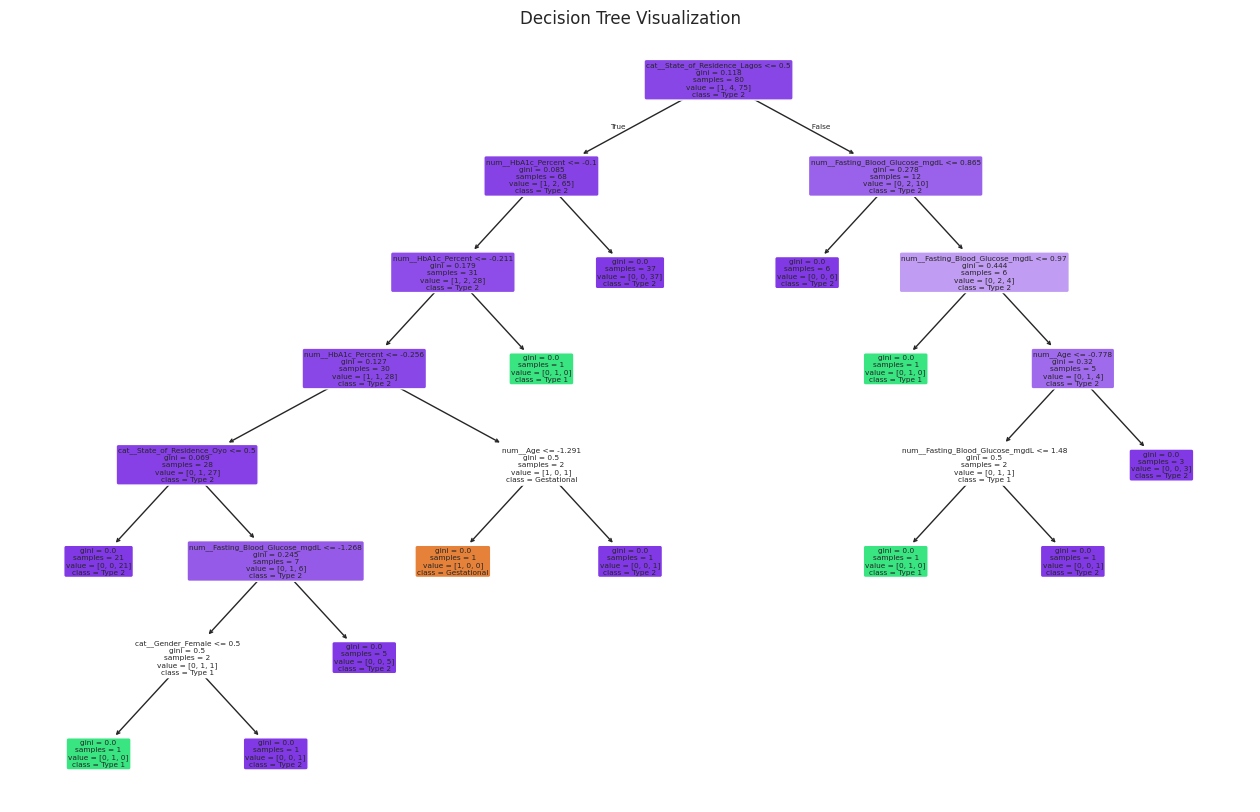

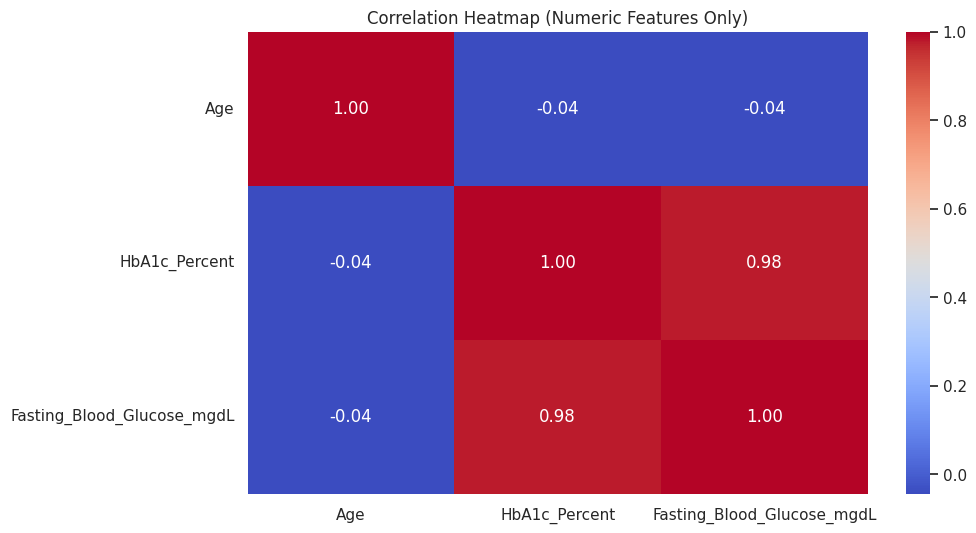

In [ ]:
from sklearn.tree import plot_tree

# Get the feature names after preprocessing
preprocessed_features = model.named_steps['preprocessor'].get_feature_names_out()

# 1. Plot the Decision Tree
plt.figure(figsize=(16, 10))
plot_tree(
    model.named_steps['classifier'],
    feature_names=preprocessed_features,
    class_names=['Type 1', 'Type 2'],
    filled=True,
    rounded=True
)
plt.title('Decision Tree Visualization')
plt.show()

# 2. Plot the Correlation Heatmap for numeric columns only
plt.figure(figsize=(10, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap (Numeric Features Only)')
plt.show()